# Training a neural network

### Load imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random

# Silence warnings
import os
import logging
import absl.logging
import warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3' 
logging.getLogger('tensorflow').setLevel(logging.ERROR)
absl.logging.set_verbosity(absl.logging.ERROR)
warnings.filterwarnings("ignore", category=UserWarning, module="tensorflow")

import tensorflow as tf
from tensorflow.keras import Sequential, layers, optimizers, regularizers
from tensorflow.keras.callbacks import EarlyStopping
from scikeras.wrappers import KerasClassifier

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.utils import class_weight
from sklearn.metrics import (
    make_scorer, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance

from datatypes import CLEAN_SQF

random.seed(123)
np.random.seed(123)
tf.random.set_seed(123)

### Split dataset into training and testing sets

In [2]:
clean_df = pd.read_csv(CLEAN_SQF)

features = clean_df.columns.difference(["USE_OF_FORCE_FLAG"]).values
X = clean_df[features]
y = clean_df["USE_OF_FORCE_FLAG"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=123
)

## Main analysis

### Create a neural network model and tune hyperparameters

In [3]:
def build_model(input_dim, neural_depth=1, neural_width=32, learning_rate=0.01):
    model = Sequential()
    model.add(layers.Input(shape=(input_dim,)))
    
    for _ in range(neural_depth):
        model.add(layers.Dense(neural_width, activation="relu", kernel_initializer="he_normal", kernel_regularizer=regularizers.l2(0.01)))
        model.add(layers.BatchNormalization())
        model.add(layers.Dropout(0.4))
        
    model.add(layers.Dense(1, activation="sigmoid"))
    
    opt = optimizers.Adam(learning_rate=learning_rate)
    
    model.compile(loss="binary_crossentropy", optimizer=opt, metrics=["Recall"])
    return model

# Handle imbalance in dataset
weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

class_weight_dict = {0: weights[0], 1: weights[1]}

# Implement early stopping
early_stop = EarlyStopping(
    monitor='val_loss', 
    patience=10, 
    restore_best_weights=True
)

# Initialize neural network model
nn = KerasClassifier(
    model=build_model,
    input_dim=X_train.shape[1],
    class_weight=class_weight_dict,
    neural_width=32,
    neural_depth=1,
    learning_rate=0.01,
    batch_size=32,
    epochs=100,
    callbacks=[early_stop],
    validation_split=0.2,
    verbose=0,
    random_state=123
)

# Define how data should be split, using a specified seed
cv_split = KFold(n_splits=5, shuffle=True, random_state=123)

# Define parameter grid for hyperparameter tuning
param_grid = {
    "neural_depth": [1, 2],
    "neural_width": [32, 64, 128],
    "learning_rate": [0.01, 0.001],
    "batch_size": [32, 64]
}

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0)
}

# Initialize GridSearchCV, with tuning based on recall (our primary metric)
grid_search = GridSearchCV(
    nn,
    param_grid=param_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_split,
    verbose=0,
    return_train_score=True,
    n_jobs=-1
)

# Run GridSearchCV
grid_search.fit(X_train, y_train)

print(f"We evaluated 3 neural widths, 2 neural depths, 2 learning rates, and 2 batch sizes across 5 cross-validation folds, totaling 120 experimental fits. Using recall as our metric, the best hyperparameters were {grid_search.best_params_}, which achieved a recall score of {grid_search.best_score_:.2f}.")

We evaluated 3 neural widths, 2 neural depths, 2 learning rates, and 2 batch sizes across 5 cross-validation folds, totaling 120 experimental fits. Using recall as our metric, the best hyperparameters were {'batch_size': 64, 'learning_rate': 0.01, 'neural_depth': 2, 'neural_width': 32}, which achieved a recall score of 0.72.


### Display results

/var/folders/s0/y03nkh8j3hq03trt7grqd9p40000gn/T/ipykernel_17709/2057418809.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f"Model {i+1}" for i in range(5)])


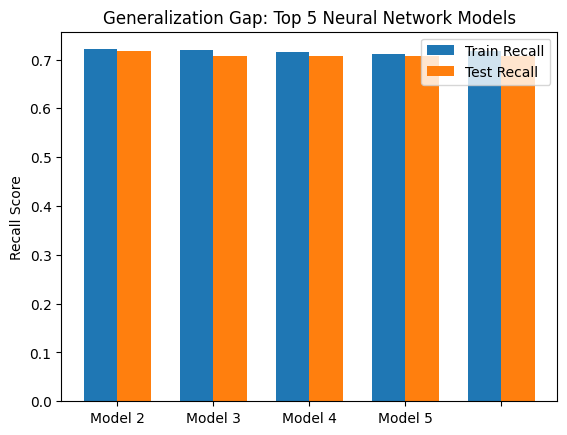

In [ ]:
# Print results
grid_search_results = pd.DataFrame(grid_search.cv_results_)

results_table = grid_search_results[[
    "param_neural_depth", "param_neural_width", "param_learning_rate", "param_batch_size",
    "mean_test_accuracy", "rank_test_accuracy",
    "mean_test_precision", "rank_test_precision",
    "mean_test_recall", "rank_test_recall",
    "mean_test_f1", "rank_test_f1"
]].copy()

# Plot top 5 models
top_5_results = grid_search_results.sort_values(by="mean_test_recall", ascending=False).head(5).reset_index(drop=True)
fig, ax = plt.subplots()

x = np.arange(len(top_5_results))
width = 0.35

rects1 = ax.bar(x - width/2, top_5_results["mean_train_recall"], width, label='Train Recall')
rects2 = ax.bar(x + width/2, top_5_results["mean_test_recall"], width, label='Test Recall')

ax.set_ylabel('Recall Score')
ax.set_title('Generalization Gap: Top 5 Neural Network Models')
ax.set_xticks(x)
ax.set_xticklabels([f"Model {i+1}" for i in range(5)])
ax.legend()
plt.show()


### Interpret model

Using the tuned hyperparameters, the permutation importance (feature contribution) for each feature is:

STOP_LOCATION_PATROL_BORO_NAME_pbbx                                        0.016180
STOP_LOCATION_PATROL_BORO_NAME_pbqs                                        0.006897
SUSPECT_REPORTED_AGE_18–24                                                 0.002387
STOP_LOCATION_PATROL_BORO_NAME_pbbs                                        0.002210
SUSPECT_REPORTED_AGE_<18                                                   0.001680
SUSPECT_RACE_DESCRIPTION_white hispanic                                    0.001149
SUSPECT_RACE_DESCRIPTION_asian_pacific islander                            0.000442
SUSPECTED_CRIME_DESCRIPTION_reckless endangerment                          0.000354
SUSPECTED_CRIME_DESCRIPTION_criminal sale of controlled substance          0.000088
SUSPECTED_CRIME_DESCRIPTION_murder                                         0.000088
SUSPECTED_CRIME_DESCRIPTION_unauthorized use of a vehic

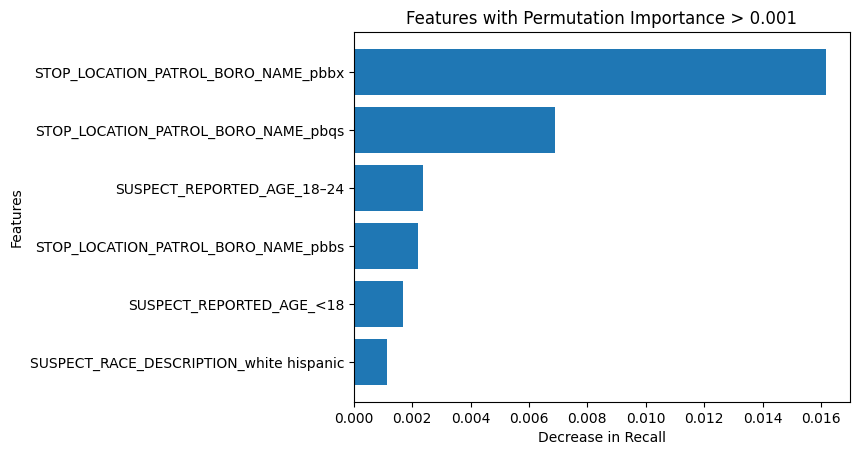

In [5]:
# Obtain the best model using the tuned GridSearchCV hyperparameters
best_model = grid_search.best_estimator_

# Extract the permutation importances from the best model
nn_importances = permutation_importance(best_model, X_test, y_test, scoring='recall', n_repeats=10, random_state=123)
nn_feature_importances = pd.Series(nn_importances.importances_mean, index=X_test.columns)

print("Using the tuned hyperparameters, the permutation importance (feature contribution) for each feature is:")
print()
print(nn_feature_importances.sort_values(ascending=False))

plot_df = nn_feature_importances[nn_feature_importances > 0.001].sort_values(ascending=True)

plt.figure()
plt.barh(plot_df.index, plot_df.values)
plt.title("Features with Permutation Importance > 0.001")
plt.xlabel("Decrease in Recall")
plt.ylabel("Features")
plt.show()

### Predict labels on test set and obtain key evaluation metrics from predictions using tuned hyperparameters (based on recall)

              precision    recall  f1-score   support

           0       0.88      0.46      0.60      4107
           1       0.28      0.77      0.41      1131

    accuracy                           0.52      5238
   macro avg       0.58      0.61      0.51      5238
weighted avg       0.75      0.52      0.56      5238



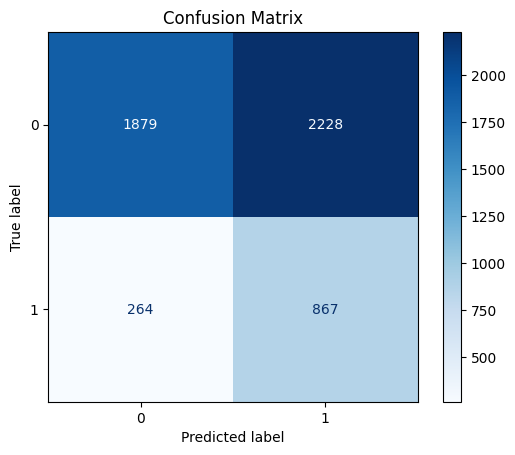

In [6]:
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred))

# Create a confusion matrix
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots()
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_model.classes_)
disp.plot(cmap="Blues", values_format="d", ax=ax)
plt.title("Confusion Matrix")
plt.show()